# Individual Structural Deviations and Regional Vulnerability Index in Epilepsy

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
import enigmatoolbox.datasets as enigma_datasets
import matplotlib.pyplot as plt

In [2]:
## 1. Load data
DATA_DIR = Path("/data/pt_03279/epilepsy_project/Epilepsy")

demo = pd.read_csv(DATA_DIR / "demo.csv", index_col=0)
ctx_tle = pd.read_csv(DATA_DIR / "ctx_tle.csv", index_col=0)

demo[["Age", "Sex", "Dx", "SDx"]] = demo[
    ["Age", "Sex", "Dx", "SDx"]
].apply(pd.to_numeric, errors="coerce")

print("Demo:", demo.shape)
print("TLE cortical thickness:", ctx_tle.shape)

## 2. Match demographics to TLE data and QC
missing = ctx_tle.index.difference(demo.index)
assert len(missing) == 0, "Some CT subjects are missing from demo."

dem_tle = demo.loc[ctx_tle.index].copy()

assert ctx_tle.index.equals(dem_tle.index)
assert ctx_tle.shape[1] == 68
assert ctx_tle.index.is_unique
assert dem_tle.index.is_unique
assert dem_tle[["Age", "Dx", "Sex"]].notna().all().all()
assert ctx_tle.notna().all().all()
assert set(dem_tle["SDx"].dropna().unique()).issubset({0, 3, 4, 5, 6})

## 3. Linear age adjustment
X = sm.add_constant(dem_tle["Age"])

age_model = sm.OLS(
    ctx_tle,
    X,
    missing="raise"
).fit()

ctx_resid = age_model.resid

hc = dem_tle["Dx"].eq(0)

hc_mean = ctx_resid.loc[hc].mean()
hc_sd = ctx_resid.loc[hc].std(ddof=1)

assert (hc_sd > 0).all(), "A control residual SD is zero."

ctx_z = (ctx_resid - hc_mean) / hc_sd

print(f"HC: {hc.sum()} | TLE: {(~hc).sum()} | Total: {len(hc)}")

Demo: (2685, 11)
TLE cortical thickness: (1743, 68)
HC: 705 | TLE: 1038 | Total: 1743


In [3]:
## 4. Load and align psychiatric reference maps

map_specs = {
    "ADHD": ("adhd", "CortThick_case_vs_controls_adult"),
    "ASD": ("asd", "CortThick_case_vs_controls_meta_analysis"),
    "BD": ("bipolar", "CortThick_case_vs_controls_adult"),
    "MDD": ("depression", "CortThick_case_vs_controls_adult"),
    "OCD": ("ocd", "CortThick_case_vs_controls_adult"),
    "SCZ": ("schizophrenia", "CortThick_case_vs_controls"),
}

ENIGMA_DIR = Path(enigma_datasets.__file__).parent / "summary_statistics"

ct_maps = {}

for map_name, (disorder, table_name) in map_specs.items():
    if map_name == "SCZ":
        table = pd.read_csv(ENIGMA_DIR / "scz_case-controls_CortThick.csv")
    else:
        table = enigma_datasets.load_summary_stats(disorder)[table_name].copy()

    ct_maps[map_name] = pd.Series(
        pd.to_numeric(table["d_icv"], errors="raise").to_numpy(),
        index=table["Structure"],
        name=map_name,
    )

CT_d = pd.concat(ct_maps, axis=1)

assert ctx_z.columns.is_unique
assert CT_d.index.is_unique
assert set(ctx_z.columns) == set(CT_d.index), "ROI names do not match."

CT_d = CT_d.reindex(ctx_z.columns)

CT_d.head()



,ADHD,ASD,BD,MDD,OCD,SCZ
L_bankssts,0.01,-0.07,-0.207,-0.058,-0.060,-0.352
L_caudalanteriorcingulate,-0.11,0.03,-0.095,-0.042,0.003,-0.119
L_caudalmiddlefrontal,-0.02,0.06,-0.266,-0.014,-0.090,-0.363
L_cuneus,0.11,-0.06,-0.056,0.047,-0.042,-0.203
L_entorhinal,-0.06,-0.24,-0.036,-0.041,-0.062,-0.203


In [4]:
## 5. Regional Vulnerability Index

RVI_tle = pd.DataFrame(index=ctx_z.index)

for disorder in CT_d.columns:
    RVI_tle[disorder] = ctx_z.T.corrwith(
        CT_d[disorder]
    )

assert RVI_tle.notna().all().all()
RVI_tle.head()

,ADHD,ASD,BD,MDD,OCD,SCZ
0,-0.288766,0.246888,0.179597,0.073168,0.252609,0.216088
1,0.035299,-0.103495,-0.297747,-0.199039,-0.101650,-0.294906
2,-0.158748,-0.203756,0.200880,-0.384856,0.105694,0.051583
3,-0.052561,0.011039,0.046539,0.150369,0.262463,0.024039
4,-0.316821,0.151855,-0.372419,-0.272800,-0.202042,-0.222118


In [5]:
## 6. Case-control differences in RVI
rvi_data = RVI_tle.join(
    dem_tle[["Dx", "Sex", "SDx"]]
).copy()

assert rvi_data.index.equals(RVI_tle.index)
assert rvi_data[RVI_tle.columns].notna().all().all()
assert set(rvi_data["Dx"].unique()) == {0, 1}

X = sm.add_constant(rvi_data[["Dx"]])
case_control_results = []

for disorder in RVI_tle.columns:
    model = sm.OLS(
        rvi_data[disorder],
        X,
        missing="raise"
    ).fit()

    ci = model.conf_int().loc["Dx"]

    case_control_results.append({
        "Disorder": disorder,
        "Beta": model.params["Dx"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx"],
        "P": model.pvalues["Dx"]
    })

case_control_results = pd.DataFrame(case_control_results)
case_control_results

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.035652,-0.056903,-0.014402,-3.290629,1.019612e-03
1,ASD,0.005896,-0.015017,0.026810,0.552972,5.803538e-01
2,BD,0.023585,0.003120,0.044049,2.260394,2.391985e-02
3,MDD,-0.066451,-0.088777,-0.044124,-5.837611,6.303081e-09
4,OCD,0.006380,-0.009135,0.021894,0.806524,4.200507e-01
5,SCZ,0.017627,-0.001092,0.036345,1.846956,6.492307e-02


In [6]:
## 7. Diagnosis × sex interaction
rvi_data["Sex_binary"] = (rvi_data["Sex"] == 1).astype(int)
rvi_data["Dx_x_Sex"] = rvi_data["Dx"] * rvi_data["Sex_binary"]

X = sm.add_constant(
    rvi_data[["Dx", "Sex_binary", "Dx_x_Sex"]]
)

interaction_results = []

for disorder in RVI_tle.columns:
    model = sm.OLS(
        rvi_data[disorder],
        X,
        missing="raise"
    ).fit()

    ci = model.conf_int().loc["Dx_x_Sex"]

    interaction_results.append({
        "Disorder": disorder,
        "Beta": model.params["Dx_x_Sex"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx_x_Sex"],
        "P": model.pvalues["Dx_x_Sex"]
    })

interaction_results = pd.DataFrame(interaction_results)
interaction_results

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.024512,-0.067237,0.018213,-1.125259,0.260635
1,ASD,0.004470,-0.037591,0.046531,0.208444,0.834906
2,BD,0.006370,-0.034767,0.047507,0.303713,0.761383
3,MDD,-0.019580,-0.064467,0.025307,-0.855543,0.392369
4,OCD,-0.004816,-0.035978,0.026346,-0.303113,0.761840
5,SCZ,0.007815,-0.029757,0.045387,0.407965,0.683350


In [7]:
## 8. Subgroup diagnosis × sex interactions

assert rvi_data.loc[rvi_data.Dx.eq(1),"SDx"].notna().all()
assert set(rvi_data.loc[rvi_data.Dx.eq(1),"SDx"].unique()).issubset({3,4,5,6})
assert set(rvi_data["Sex"].unique()) == {1,2}

subgroups = {
    "Left TLE": [3,5],
    "Right TLE": [4,6],
    "MTS": [3,4],
    "Non-lesional": [5,6]
}

subgroup_interactions = []
subgroup_counts = []

for subgroup,codes in subgroups.items():

    patients = rvi_data.Dx.eq(1) & rvi_data.SDx.isin(codes)
    d = rvi_data[rvi_data.Dx.eq(0) | patients].copy()

    subgroup_counts.append({
        "Subgroup": subgroup,
        "N": patients.sum(),
        "F": (patients & rvi_data.Sex.eq(2)).sum(),
        "M": (patients & rvi_data.Sex.eq(1)).sum()
    })

    d["Sex_binary"] = d["Sex"].eq(1).astype(int)
    d["Dx_x_Sex"] = d["Dx"] * d["Sex_binary"]
    X = sm.add_constant(d[["Dx","Sex_binary","Dx_x_Sex"]])

    for disorder in RVI_tle.columns:
        model = sm.OLS(d[disorder],X,missing="raise").fit()

        subgroup_interactions.append({
            "Subgroup": subgroup,
            "Disorder": disorder,
            "Beta": model.params["Dx_x_Sex"],
            "T": model.tvalues["Dx_x_Sex"],
            "P": model.pvalues["Dx_x_Sex"]
        })

subgroup_counts = pd.DataFrame(subgroup_counts)
subgroup_interactions = pd.DataFrame(subgroup_interactions)

SUBGROUP_LIM = subgroup_interactions["T"].abs().max() * 1.1

display(subgroup_counts)
subgroup_interactions

,Subgroup,N,F,M
0,Left TLE,610,336,274
1,Right TLE,428,235,193
2,MTS,582,322,260
3,Non-lesional,456,249,207


,Subgroup,Disorder,Beta,T,P
0,Left TLE,ADHD,-0.042660,-1.717437,0.086136
1,Left TLE,ASD,0.001331,0.054210,0.956776
2,Left TLE,BD,0.009905,0.417357,0.676486
3,Left TLE,MDD,-0.020677,-0.797425,0.425348
4,Left TLE,OCD,0.001653,0.091729,0.926928
5,Left TLE,SCZ,0.011362,0.527262,0.598101
6,Right TLE,ADHD,0.001371,0.050615,0.959641
7,Right TLE,ASD,0.008967,0.326823,0.743862
8,Right TLE,BD,0.001387,0.053091,0.957669
9,Right TLE,MDD,-0.018007,-0.629395,0.529218


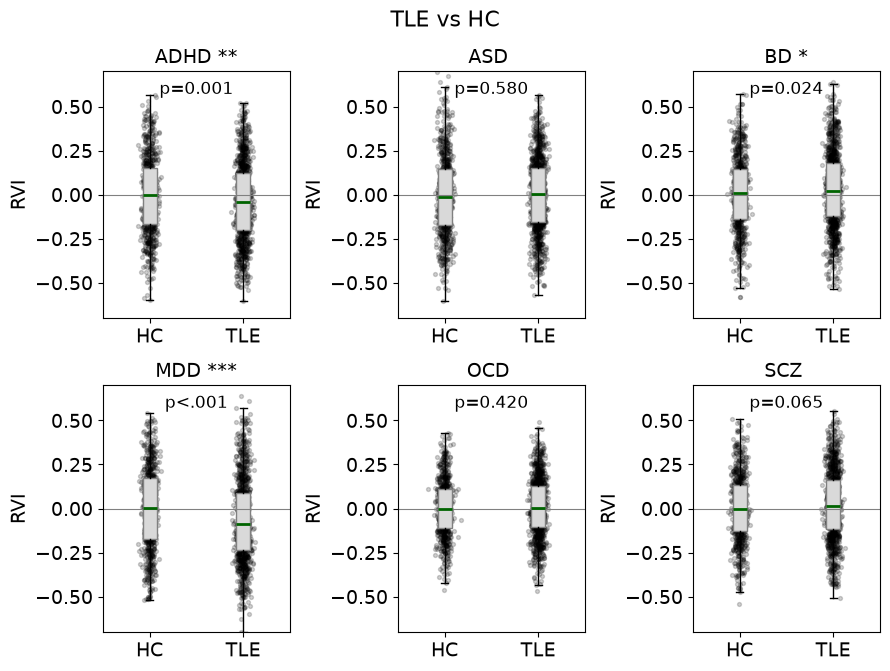

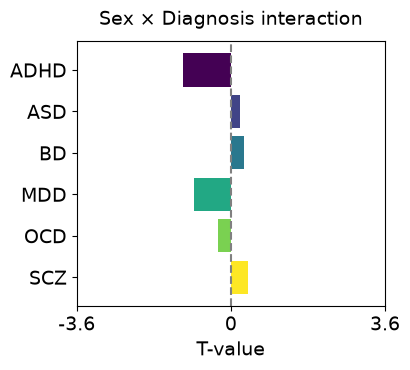

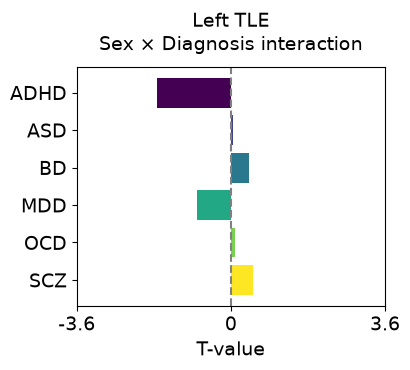

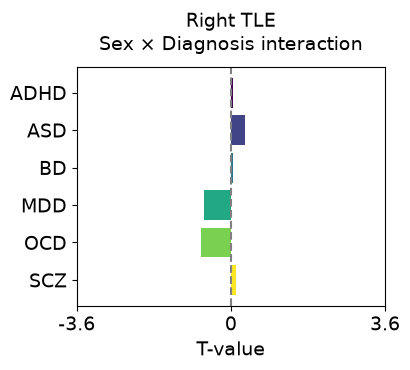

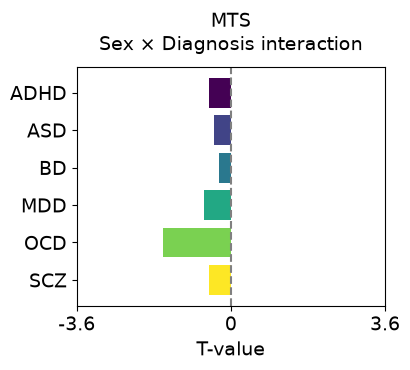

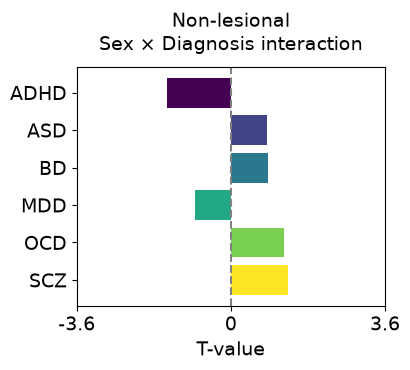

In [8]:
## 9. RVI visualization
plt.close("all")

order = list(RVI_tle.columns)
star = lambda p: "***" if p<.001 else "**" if p<.01 else "*" if p<.05 else ""
pfmt = lambda p: "p<.001" if p<.001 else f"p={p:.3f}"

RVI_LIM = .7
T_LIM = 3.6
FONT = 14

# TLE vs HC
fig,axs = plt.subplots(2,3,figsize=(9,6.8))

for ax,d in zip(axs.flat,order):
    v = [rvi_data.loc[rvi_data.Dx==x,d] for x in (0,1)]
    p = case_control_results.loc[
        case_control_results.Disorder.eq(d),"P"
    ].iloc[0]

    bp = ax.boxplot(
        v,tick_labels=["HC","TLE"],
        showfliers=False,patch_artist=True,
        medianprops={"color":"darkgreen","linewidth":2}
    )

    for b in bp["boxes"]:
        b.set(facecolor="#d9d9d9",edgecolor="gray")

    for i,y in enumerate(v,1):
        ax.scatter(
            np.random.normal(i,.04,len(y)),y,
            s=8,alpha=.18,color="black"
        )

    ax.axhline(0,color="gray",lw=.8)
    ax.set_ylim(-RVI_LIM,RVI_LIM)
    ax.set_title(f"{d} {star(p)}",fontsize=FONT)
    ax.set_ylabel("RVI",fontsize=FONT)
    ax.tick_params(axis="both",labelsize=FONT)
    ax.text(
        .5,.96,pfmt(p),transform=ax.transAxes,
        ha="center",va="top",fontsize=12
    )

fig.suptitle("TLE vs HC",fontsize=16)
fig.tight_layout()
fig.savefig("TLE_vs_HC.png",dpi=300,bbox_inches="tight")
plt.show()


# Interaction plots
def barfig(df,title,name):
    d = df.set_index("Disorder").loc[order]
    fig,ax = plt.subplots(figsize=(4.2,3.8))

    bars = ax.barh(
        d.index,d["T"],
        color=plt.cm.viridis(np.linspace(0,1,6))
    )

    ax.axvline(0,color="gray",ls="--")
    ax.set_xlim(-T_LIM,T_LIM)
    ax.set_xticks(
        [-T_LIM,0,T_LIM],
        labels=[f"{-T_LIM:g}","0",f"{T_LIM:g}"]
    )

    ax.tick_params(axis="both",labelsize=FONT)
    ax.set_xlabel("T-value",fontsize=FONT)
    ax.set_title(
        title.replace(": ","\n"),
        fontsize=FONT,pad=12
    )

    for b,p in zip(bars,d["P"]):
        if p<.05:
            ax.text(
                b.get_width()/2,b.get_y()+b.get_height()/2,
                f"{star(p)}\n{pfmt(p)}",
                ha="center",va="center",fontsize=12,
                color="white",fontweight="bold"
            )

    ax.invert_yaxis()
    fig.tight_layout()
    fig.savefig(name+".png",dpi=300,bbox_inches="tight")
    plt.show()


# Overall TLE
barfig(
    interaction_results,
    "Sex × Diagnosis interaction",
    "Sex_Dx"
)

# TLE subgroups
for subgroup,name in {
    "Left TLE":"Left_TLE_Sex_Dx",
    "Right TLE":"Right_TLE_Sex_Dx",
    "MTS":"MTS_Sex_Dx",
    "Non-lesional":"Nonlesional_Sex_Dx"
}.items():

    d = subgroup_interactions[
        subgroup_interactions.Subgroup.eq(subgroup)
    ]
    barfig(d,f"{subgroup}: Sex × Diagnosis interaction",name)